print("Welcome to Financial Fraud Detection Project!")

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries installed successfully!")

All libraries installed successfully!


In [9]:
import os

print(os.getcwd())

c:\Users\abishake\OneDrive\Desktop\Financial_fraud_detection_system\notebooks


In [10]:
import os

print(os.listdir(".."))

['.venv', '.venv-1', 'notebooks']


In [12]:
import pandas as pd

df = pd.read_csv("datasets/creditcard.csv")

print(df.head())
print(df.shape)

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [14]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [15]:
print("Total duplicate records:", df.duplicated().sum())

Total duplicate records: 1081


In [16]:
print(df["Class"].value_counts())

Class
0    284315
1       492
Name: count, dtype: int64


In [17]:
fraud_percentage = (
    df["Class"].value_counts(normalize=True) * 100
)

print(fraud_percentage)

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [18]:
df.describe()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.596686e-16,-3.576577e-16,2.618565e-16,4.473116e-15,5.109395e-16,1.686100e-15,-3.657409e-16,-1.221465e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [19]:
print(df.columns)

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')


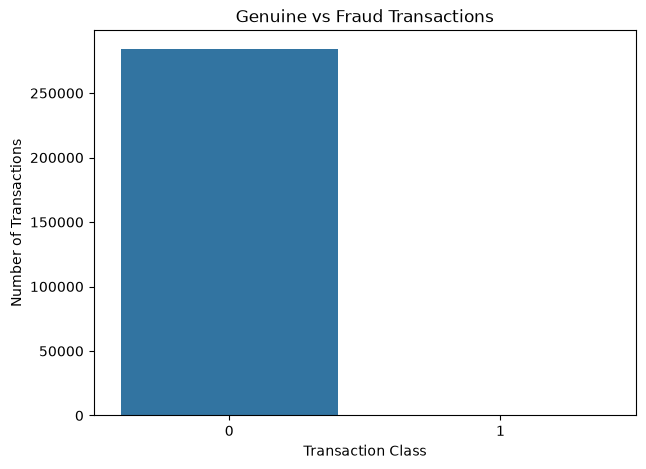

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7,5))

sns.countplot(data=df, x="Class")

plt.title("Genuine vs Fraud Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

plt.show()

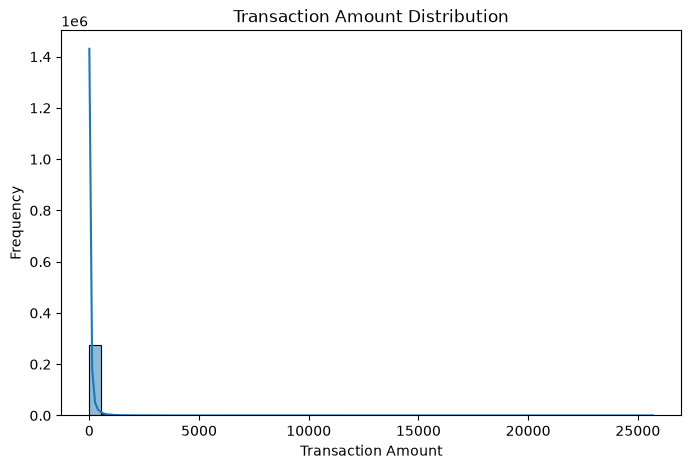

In [21]:
plt.figure(figsize=(8,5))

sns.histplot(df["Amount"], bins=50, kde=True)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

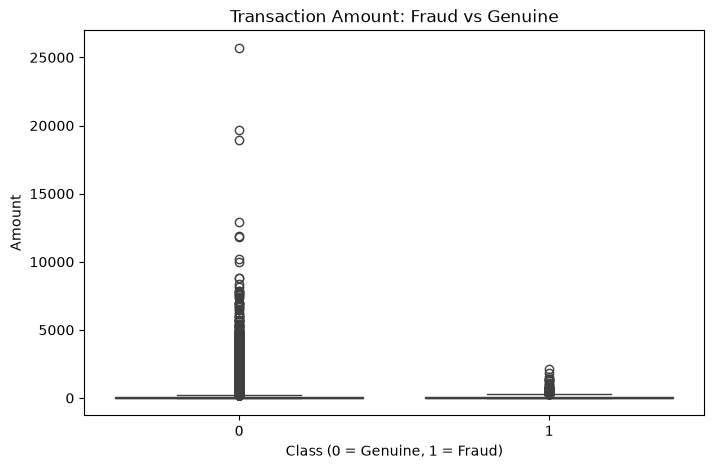

In [22]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x="Class", y="Amount")

plt.title("Transaction Amount: Fraud vs Genuine")
plt.xlabel("Class (0 = Genuine, 1 = Fraud)")
plt.ylabel("Amount")

plt.show()

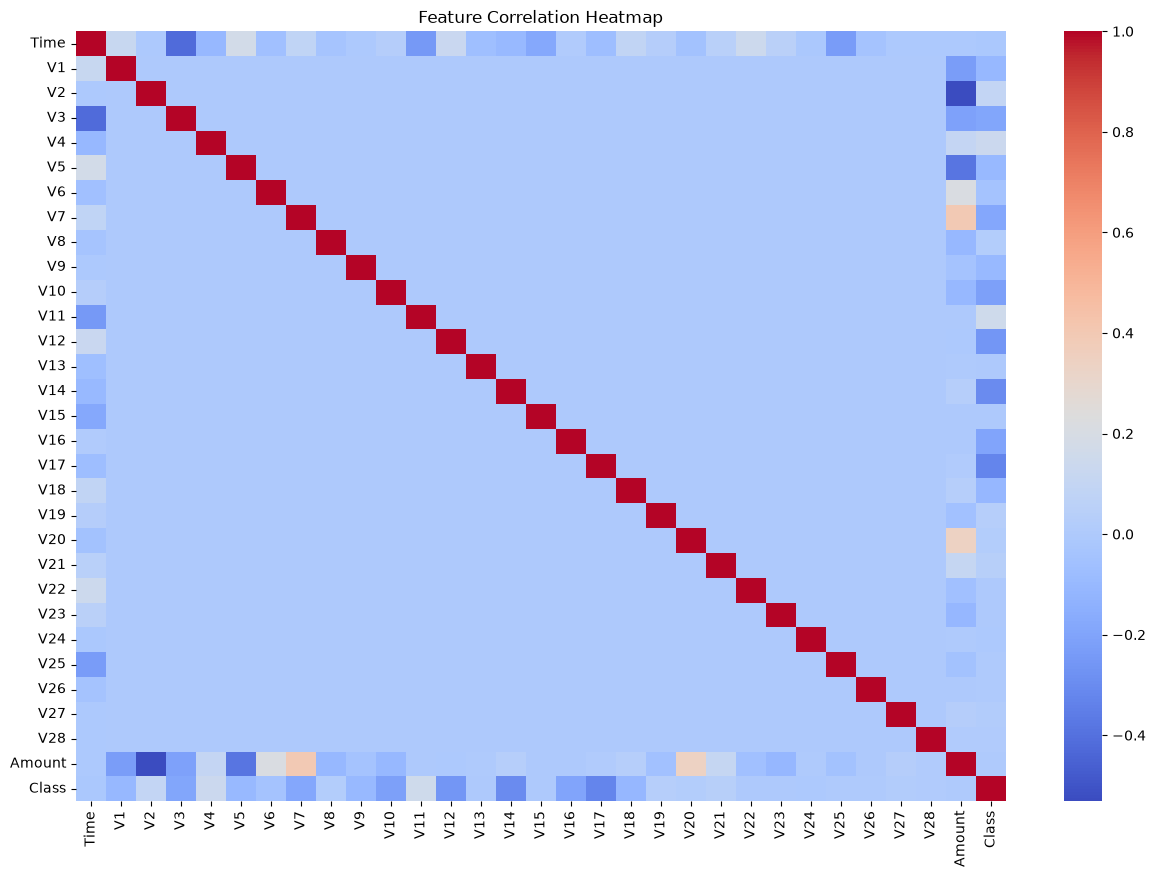

In [23]:
plt.figure(figsize=(15,10))

correlation = df.corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=False
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [4]:
import pandas as pd

df = pd.read_csv("datasets/creditcard.csv")

print(df.head())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [5]:
print(type(df))
print(df.shape)

<class 'pandas.DataFrame'>
(284807, 31)


In [6]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape: (284807, 31)

Missing Values:
0

Duplicate Rows:
1081


In [7]:
print(df.groupby("Class")["Amount"].describe())

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


In [8]:
X = df.drop("Class", axis=1)
y = df["Class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (284807, 30)
Target shape: (284807,)


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (227845, 30)
Testing Features: (56962, 30)
Training Target: (227845,)
Testing Target: (56962,)


In [10]:
print("Original Dataset:")
print(y.value_counts())

print("\nTraining Dataset:")
print(y_train.value_counts())

print("\nTesting Dataset:")
print(y_test.value_counts())

Original Dataset:
Class
0    284315
1       492
Name: count, dtype: int64

Training Dataset:
Class
0    227451
1       394
Name: count, dtype: int64

Testing Dataset:
Class
0    56864
1       98
Name: count, dtype: int64


In [11]:
print("Original Fraud %:", y.mean() * 100)

print("Training Fraud %:", y_train.mean() * 100)

print("Testing Fraud %:", y_test.mean() * 100)

Original Fraud %: 0.1727485630620034
Training Fraud %: 0.17292457591783889
Testing Fraud %: 0.17204452090867595


In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [13]:
X_train = X_train.copy()
X_test = X_test.copy()

X_train[["Time", "Amount"]] = scaler.fit_transform(
    X_train[["Time", "Amount"]]
)

X_test[["Time", "Amount"]] = scaler.transform(
    X_test[["Time", "Amount"]]
)

In [14]:
print(X_train[["Time", "Amount"]].describe())

               Time        Amount
count  2.278450e+05  2.278450e+05
mean  -1.409578e-16  3.742243e-17
std    1.000002e+00  1.000002e+00
min   -1.998073e+00 -3.516894e-01
25%   -8.561495e-01 -3.291944e-01
50%   -2.122647e-01 -2.639429e-01
75%    9.366285e-01 -4.262209e-02
max    1.640549e+00  1.021170e+02


In [15]:
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nMissing Values in Training:", X_train.isnull().sum().sum())
print("Missing Values in Testing:", X_test.isnull().sum().sum())

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data Shape: (227845, 30)
Testing Data Shape: (56962, 30)

Missing Values in Training: 0
Missing Values in Testing: 0

Training Target Distribution:
Class
0    227451
1       394
Name: count, dtype: int64

Testing Target Distribution:
Class
0    56864
1       98
Name: count, dtype: int64


In [16]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

In [18]:
model.fit(X_train, y_train)
print("Model Training Completed Successfully!")

Model Training Completed Successfully!


In [19]:
y_pred = model.predict(X_test)

print("First 20 Predictions:")
print(y_pred[:20])

First 20 Predictions:
[0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1]


In [20]:
comparison = pd.DataFrame({
    "Actual": y_test.values[:20],
    "Predicted": y_pred[:20]
})

print(comparison)

    Actual  Predicted
0        0          0
1        0          0
2        0          0
3        0          0
4        0          1
5        0          0
6        0          0
7        0          0
8        0          0
9        0          0
10       0          0
11       0          0
12       0          0
13       0          0
14       0          0
15       0          0
16       0          0
17       0          0
18       0          0
19       0          1


Confusion Matrix:
[[55478  1386]
 [    8    90]]


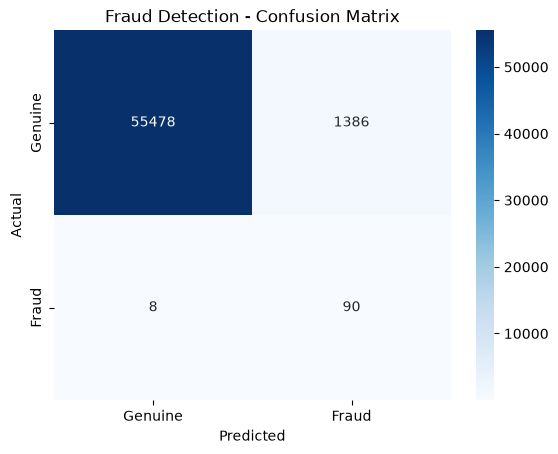

In [21]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Genuine", "Fraud"],
    yticklabels=["Genuine", "Fraud"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Fraud Detection - Confusion Matrix")
plt.show()

In [22]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962



In [23]:
from sklearn.metrics import roc_auc_score

y_prob = model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", roc_auc)

ROC-AUC Score: 0.9721687370080279


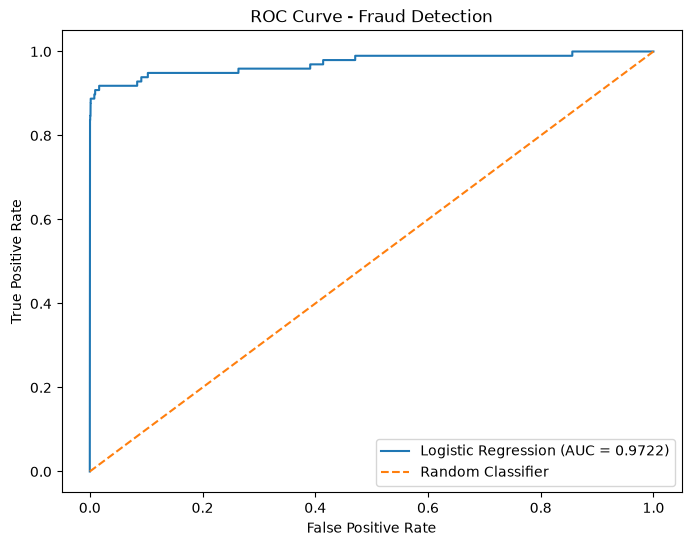

ROC-AUC Score: 0.9721687370080279


In [24]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_score:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Fraud Detection")

plt.legend()
plt.show()

print("ROC-AUC Score:", auc_score)

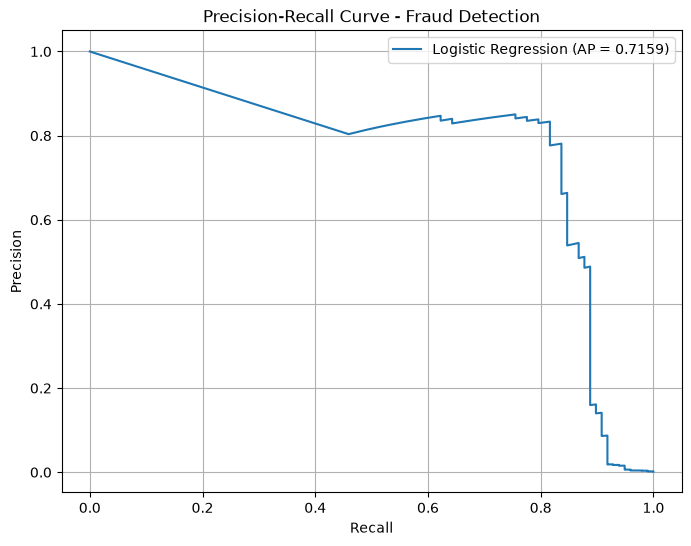

Average Precision Score: 0.7159122424484009


In [25]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)
import matplotlib.pyplot as plt

precision, recall, thresholds = precision_recall_curve(
    y_test, y_prob
)

pr_auc = average_precision_score(y_test, y_prob)

plt.figure(figsize=(8, 6))

plt.plot(recall, precision, label=f"Logistic Regression (AP = {pr_auc:.4f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Fraud Detection")

plt.legend()
plt.grid()
plt.show()

print("Average Precision Score:", pr_auc)

In [26]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

In [27]:
rf_model.fit(X_train, y_train)

print("Random Forest Training Completed!")

Random Forest Training Completed!


In [28]:
rf_pred = rf_model.predict(X_test)

print("First 20 Random Forest Predictions:")
print(rf_pred[:20])

First 20 Random Forest Predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [29]:
from sklearn.metrics import classification_report

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.91      0.79      0.84        98

    accuracy                           1.00     56962
   macro avg       0.95      0.89      0.92     56962
weighted avg       1.00      1.00      1.00     56962



In [30]:
from sklearn.metrics import roc_auc_score

rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest ROC-AUC:",
      roc_auc_score(y_test, rf_prob))

Random Forest ROC-AUC: 0.9573101557026863


In [31]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],

    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, rf_pred)
    ],

    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, rf_pred)
    ],

    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, rf_pred)
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, rf_prob)
    ],

    "Average Precision": [
        average_precision_score(y_test, y_prob),
        average_precision_score(y_test, rf_prob)
    ]
})

print(results.round(4))

                 Model  Precision  Recall  F1 Score  ROC-AUC  \
0  Logistic Regression     0.0610  0.9184    0.1144   0.9722   
1        Random Forest     0.9059  0.7857    0.8415   0.9573   

   Average Precision  
0             0.7159  
1             0.8629  


In [32]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(10))

   Feature  Importance
14     V14    0.191038
10     V10    0.106849
4       V4    0.105643
12     V12    0.097603
17     V17    0.090339
3       V3    0.065919
11     V11    0.046342
16     V16    0.044655
2       V2    0.038335
9       V9    0.025445


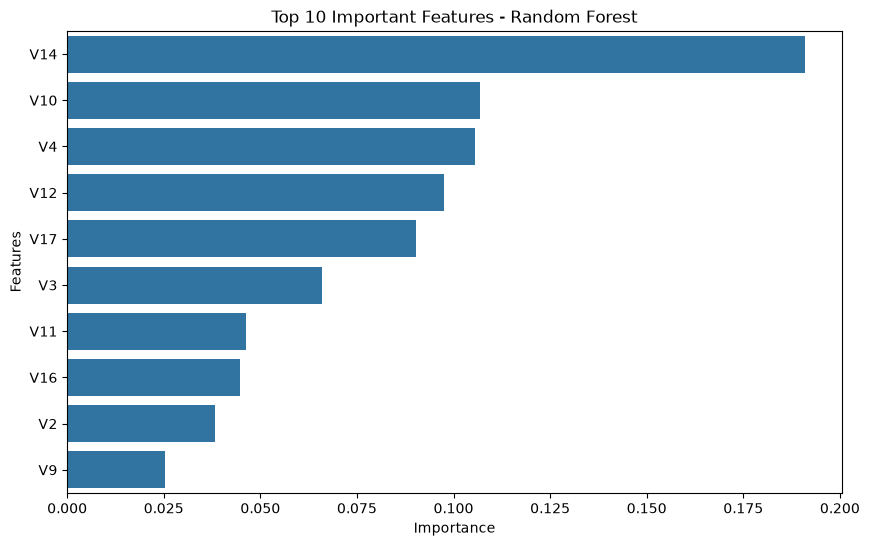

In [33]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()

In [34]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

In [35]:
param_grid = {
    "C": [0.01, 0.1, 1, 10],
    "class_weight": ["balanced"]
}

In [36]:
grid_search = GridSearchCV(
    estimator=LogisticRegression(max_iter=1000, random_state=42),
    param_grid=param_grid,
    scoring="average_precision",
    cv=3,
    n_jobs=-1,
    verbose=1
)

In [37]:
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Average Precision:", grid_search.best_score_)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Parameters: {'C': 1, 'class_weight': 'balanced'}
Best CV Average Precision: 0.7554514270719718


In [38]:
best_model = grid_search.best_estimator_

print("Best Model:", best_model)

Best Model: LogisticRegression(C=1, class_weight='balanced', max_iter=1000, random_state=42)


In [39]:
y_tuned_pred = best_model.predict(X_test)

y_tuned_prob = best_model.predict_proba(X_test)[:, 1]

print("Tuned Model Predictions:")
print(y_tuned_pred[:20])

Tuned Model Predictions:
[0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1]


In [40]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_tuned_pred))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962



In [41]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

print("ROC-AUC:",
      roc_auc_score(y_test, y_tuned_prob))

print("Average Precision:",
      average_precision_score(y_test, y_tuned_prob))

ROC-AUC: 0.9721687370080279
Average Precision: 0.7159122424484009


In [42]:
comparison = pd.DataFrame({
    "Model": ["Original Logistic Regression", "Tuned Logistic Regression"],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_tuned_pred)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_tuned_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, y_tuned_prob)
    ],
    "Average Precision": [
        average_precision_score(y_test, y_prob),
        average_precision_score(y_test, y_tuned_prob)
    ]
})

print(comparison.round(4))

                          Model  Recall  F1 Score  ROC-AUC  Average Precision
0  Original Logistic Regression  0.9184    0.1144   0.9722             0.7159
1     Tuned Logistic Regression  0.9184    0.1144   0.9722             0.7159


In [43]:
import numpy as np

threshold = 0.3

y_threshold_pred = (
    y_tuned_prob >= threshold
).astype(int)

print("First 20 Threshold Predictions:")
print(y_threshold_pred[:20])

First 20 Threshold Predictions:
[0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1]


In [44]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_threshold_pred
))

              precision    recall  f1-score   support

           0       1.00      0.94      0.97     56864
           1       0.03      0.92      0.05        98

    accuracy                           0.94     56962
   macro avg       0.51      0.93      0.51     56962
weighted avg       1.00      0.94      0.97     56962



In [45]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

threshold_results = []

for t in thresholds:

    predictions = (y_tuned_prob >= t).astype(int)

    threshold_results.append({
        "Threshold": t,
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4))

   Threshold  Precision  Recall  F1 Score
0        0.1     0.0081  0.9490    0.0161
1        0.2     0.0164  0.9388    0.0322
2        0.3     0.0273  0.9184    0.0530
3        0.4     0.0421  0.9184    0.0804
4        0.5     0.0610  0.9184    0.1144
5        0.6     0.0867  0.9082    0.1582
6        0.7     0.1214  0.9082    0.2142


In [46]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    random_state=42,
    sampling_strategy=0.5
)

In [47]:
X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
Class
0    227451
1       394
Name: count, dtype: int64

After SMOTE:
Class
0    227451
1    113725
Name: count, dtype: int64


In [48]:
smote_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

smote_model.fit(X_train_smote, y_train_smote)

print("SMOTE Model Training Completed!")

SMOTE Model Training Completed!


In [49]:
smote_pred = smote_model.predict(X_test)

smote_prob = smote_model.predict_proba(X_test)[:, 1]

print("First 20 SMOTE Predictions:")
print(smote_pred[:20])

First 20 SMOTE Predictions:
[0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [50]:
from sklearn.metrics import classification_report

print(classification_report(y_test, smote_pred))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56864
           1       0.11      0.90      0.19        98

    accuracy                           0.99     56962
   macro avg       0.55      0.94      0.59     56962
weighted avg       1.00      0.99      0.99     56962



In [51]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("SMOTE Precision:", precision_score(y_test, smote_pred))
print("SMOTE Recall:", recall_score(y_test, smote_pred))
print("SMOTE F1 Score:", f1_score(y_test, smote_pred))
print("SMOTE ROC-AUC:", roc_auc_score(y_test, smote_prob))
print("SMOTE Average Precision:", average_precision_score(y_test, smote_prob))

SMOTE Precision: 0.10602409638554217
SMOTE Recall: 0.8979591836734694
SMOTE F1 Score: 0.1896551724137931
SMOTE ROC-AUC: 0.9681968542200222
SMOTE Average Precision: 0.7155820163944554


In [52]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "SMOTE Logistic Regression"
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, rf_pred),
        precision_score(y_test, smote_pred)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, rf_pred),
        recall_score(y_test, smote_pred)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, rf_pred),
        f1_score(y_test, smote_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, rf_prob),
        roc_auc_score(y_test, smote_prob)
    ],
    "Average Precision": [
        average_precision_score(y_test, y_prob),
        average_precision_score(y_test, rf_prob),
        average_precision_score(y_test, smote_prob)
    ]
})

print(model_comparison.round(4))

                       Model  Precision  Recall  F1 Score  ROC-AUC  \
0        Logistic Regression     0.0610  0.9184    0.1144   0.9722   
1              Random Forest     0.9059  0.7857    0.8415   0.9573   
2  SMOTE Logistic Regression     0.1060  0.8980    0.1897   0.9682   

   Average Precision  
0             0.7159  
1             0.8629  
2             0.7156  


In [53]:
import shap
import numpy as np

In [54]:
explainer = shap.TreeExplainer(rf_model)

sample_data = X_test.iloc[:100]

shap_values = explainer.shap_values(sample_data)

In [55]:
print("SHAP output type:", type(shap_values))

if isinstance(shap_values, list):
    fraud_shap_values = shap_values[1]
elif shap_values.ndim == 3:
    fraud_shap_values = shap_values[:, :, 1]
else:
    fraud_shap_values = shap_values

SHAP output type: <class 'numpy.ndarray'>


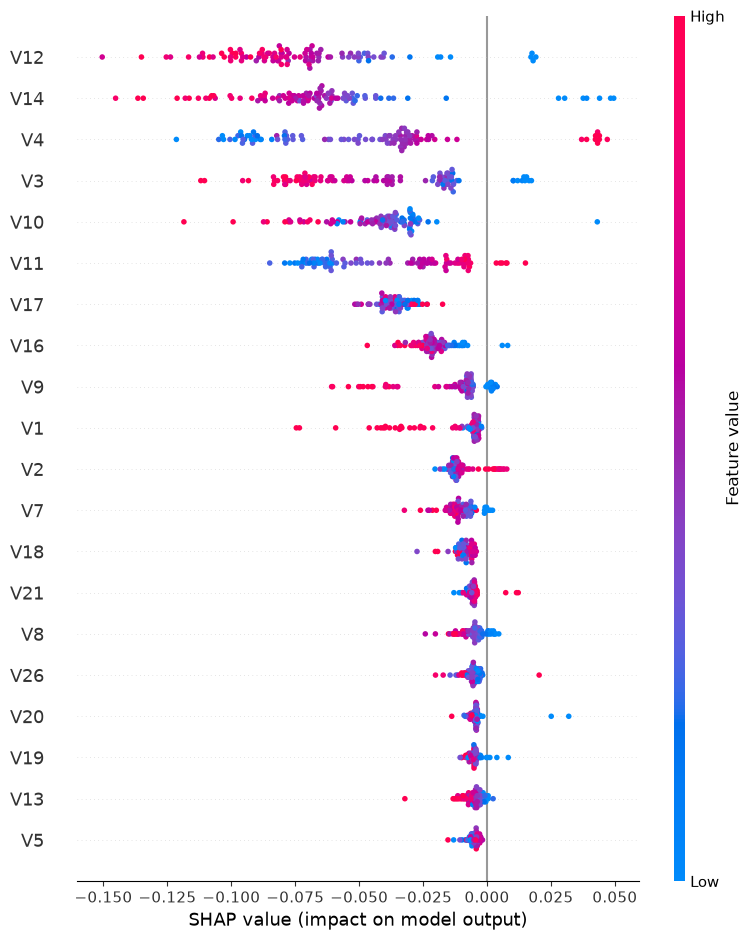

In [56]:
shap.summary_plot(
    fraud_shap_values,
    sample_data
)

In [57]:
import joblib
import os


In [58]:
os.makedirs("models", exist_ok=True)

print("Models folder created successfully!")

Models folder created successfully!


In [59]:
joblib.dump(rf_model, "models/random_forest_model.pkl")

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [60]:
joblib.dump(scaler, "models/scaler.pkl")

print("Scaler saved successfully!")

Scaler saved successfully!


In [61]:
loaded_model = joblib.load("models/random_forest_model.pkl")

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [62]:
test_prediction = loaded_model.predict(X_test.iloc[:5])

print("Predictions:", test_prediction)

Predictions: [0 0 0 0 0]


In [63]:
import streamlit as st

st.set_page_config(
    page_title="Financial Fraud Detection",
    page_icon="🔐",
    layout="wide"
)

st.title("🔐 Financial Fraud Detection System")

st.write(
    "An AI-powered application for identifying "
    "potentially fraudulent financial transactions."
)

st.success("Application is running successfully!")

st.subheader("Project Overview")

col1, col2, col3 = st.columns(3)

col1.metric("ML Models", "3")
col2.metric("Dataset Transactions", "284,807")
col3.metric("Fraud Cases", "492")

2026-11-20 15:26:40.807 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-20 15:26:40.809 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-20 15:26:41.448 
  command:

    streamlit run c:\Users\abishake\OneDrive\Desktop\Financial_fraud_detection_system\.venv\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-11-20 15:26:41.450 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-20 15:26:41.452 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-20 15:26:41.453 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-20 15:26:41.454 Thread 'MainThread': missing Script

DeltaGenerator()